# 06.4 · Hierarchical clustering and dendrograms

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/06-unsupervised/04-hierarchical/lesson.ipynb)

Read the [README](README.md) and do the single-linkage merges on paper first. This notebook:

1. Builds the distance matrix and the merge history for the five customers under four linkages.
2. Draws dendrograms and cuts them.
3. Clusters a sample of real customers and compares linkages, and Ward with K-Means.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

## 1. Five customers and their distance matrix

In [2]:
names = list("ABCDE")
points = np.array([[1, 1], [2, 1], [5, 4], [6, 5], [6, 8]], dtype=float)   # (orders, items per order)

In [3]:
from scipy.spatial.distance import pdist, squareform

dist = pd.DataFrame(squareform(pdist(points)), index=names, columns=names)
dist.round(2)

,A,B,C,D,E
A,0.0,1.00,5.00,6.40,8.60
B,1.0,0.00,4.24,5.66,8.06
C,5.0,4.24,0.00,1.41,4.12
D,6.4,5.66,1.41,0.00,3.00
E,8.6,8.06,4.12,3.00,0.00


## 2. The merge history

`linkage` returns one row per merge: the two groups joined (numbered: 0–4 are the customers, 5 is the first new group, 6 the second, …), the height, and the size of the new group.

In [4]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Z = linkage(points, method="single")
pd.DataFrame(Z, columns=["group 1", "group 2", "height", "size"]).round(2)

,group 1,group 2,height,size
0,0.0,1.0,1.00,2.0
1,2.0,3.0,1.41,2.0
2,4.0,6.0,3.00,3.0
3,5.0,7.0,4.24,5.0


Read it against your paper: customers 0 and 1 (A, B) merge at 1.00 into group 5; 2 and 3 (C, D) at 1.41 into group 6; group 6 and customer 4 (E) at 3.00 into group 7; groups 5 and 7 at 4.24.

### All four linkages

In [5]:
heights = {}
for method in ["single", "complete", "average", "ward"]:
    heights[method] = linkage(points, method=method)[:, 2]
pd.DataFrame(heights, index=["{A,B}", "{C,D}", "{C,D}+E", "everyone"]).round(2)

,single,complete,average,ward
"{A,B}",1.00,1.00,1.00,1.00
"{C,D}",1.41,1.41,1.41,1.41
"{C,D}+E",3.00,4.12,3.56,4.08
everyone,4.24,8.60,6.33,9.69


Same order of merges, different heights. Complete linkage's last merge (8.60) is the distance between the two farthest customers, A and E.

## 3. Dendrograms

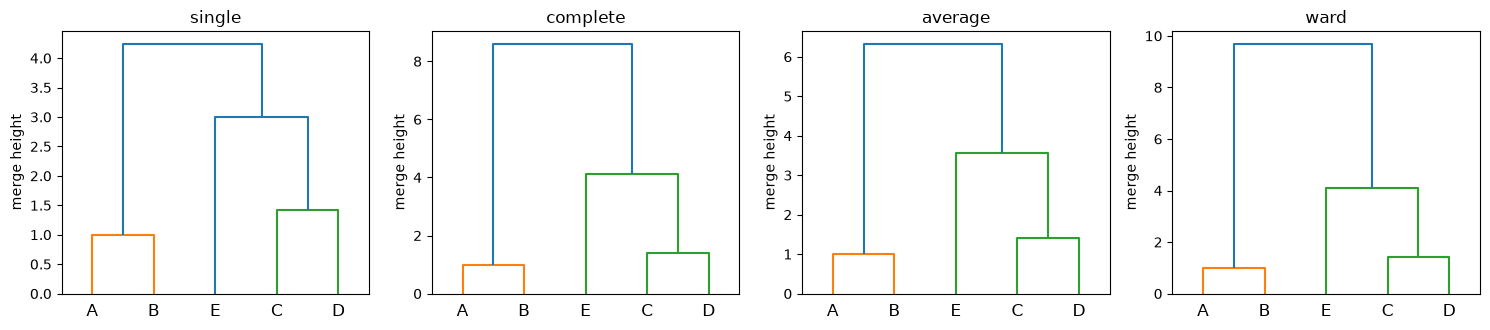

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=False)
for ax, method in zip(axes, ["single", "complete", "average", "ward"]):
    dendrogram(linkage(points, method=method), labels=names, ax=ax)
    ax.set_title(method); ax.set_ylabel("merge height")
plt.tight_layout(); plt.show()

**Cutting the tree.** Ask for 2 clusters, or cut at a height:

In [7]:
Z = linkage(points, method="single")
print("2 clusters:          ", fcluster(Z, t=2, criterion="maxclust"))
print("cut at height 2.0:   ", fcluster(Z, t=2.0, criterion="distance"))
print("cut at height 3.5:   ", fcluster(Z, t=3.5, criterion="distance"))

2 clusters:           [1 1 2 2 2]
cut at height 2.0:    [1 1 2 2 3]
cut at height 3.5:    [1 1 2 2 2]


A low cut (2.0) leaves three groups: {A, B}, {C, D} and E alone. A higher cut (3.5) has merged E into {C, D}. You choose the level after seeing the whole tree, instead of choosing $k$ before.

## 4. Real customers

A random sample of 300 customers, RFM logged and standardised (scaled on the sample itself).

In [8]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

snapshot = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)    # 2011-12-10
rfm = sales.groupby("Customer ID").agg(
    recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum"))
print(f"{len(sales):,} rows, {len(rfm):,} customers, snapshot {snapshot.date()}")

392,693 rows, 4,338 customers, snapshot 2011-12-10


In [9]:
from sklearn.preprocessing import StandardScaler

sample = rfm.sample(300, random_state=42)
Xs = StandardScaler().fit_transform(np.log1p(sample))
print("sample:", Xs.shape)

sample: (300, 3)


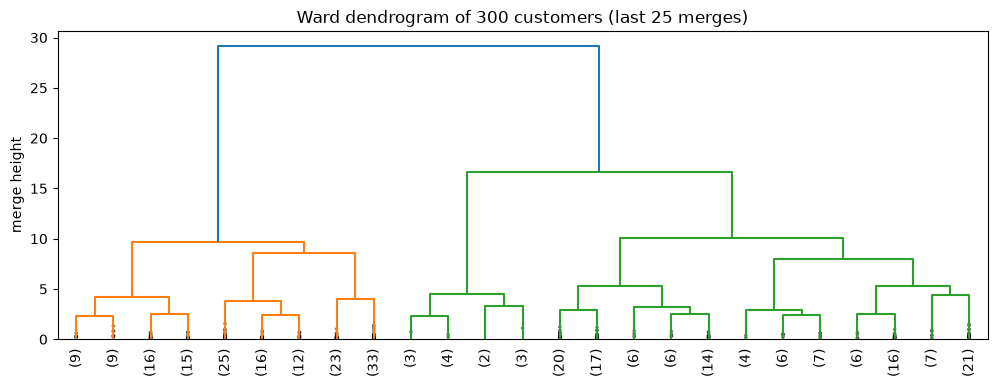

In [10]:
Z_ward = linkage(Xs, method="ward")
plt.figure(figsize=(12, 4))
dendrogram(Z_ward, truncate_mode="lastp", p=25, leaf_rotation=90, show_contracted=True)
plt.title("Ward dendrogram of 300 customers (last 25 merges)"); plt.ylabel("merge height")
plt.show()

Numbers in brackets at the bottom are how many customers sit under each branch. Look for long vertical lines: they mean a group stayed separate for a long time before being forced together.

### Comparing linkages

In [11]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

for method in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=4, linkage=method).fit_predict(Xs)
    print(f"{method:<9} sizes {sorted(np.bincount(lab).tolist(), reverse=True)}   silhouette {silhouette_score(Xs, lab):.3f}")

ward      sizes [158, 67, 63, 12]   silhouette 0.331
complete  sizes [148, 95, 45, 12]   silhouette 0.353
average   sizes [283, 12, 4, 1]   silhouette 0.265
single    sizes [296, 2, 1, 1]   silhouette 0.581


Single linkage: the best silhouette and a useless answer (one cluster of 296 plus three lone customers). Average linkage is nearly as lopsided. Ward and complete give groups of usable size.

### What Ward found

In [12]:
ward4 = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(Xs)
sample.assign(cluster=ward4).groupby("cluster").agg(
    customers=("recency", "size"), recency=("recency", "mean"),
    frequency=("frequency", "mean"), monetary=("monetary", "mean")).sort_values("monetary").round(0)

,customers,recency,frequency,monetary
cluster,,,,
0,158,152.0,2.0,444.0
1,67,10.0,5.0,1687.0
3,63,49.0,5.0,2256.0
2,12,7.0,44.0,27485.0


In [13]:
print("Ward with 2 clusters, sizes:", sorted(np.bincount(fcluster(Z_ward, 2, "maxclust") - 1).tolist(), reverse=True))
print("Ward with 3 clusters, sizes:", sorted(np.bincount(fcluster(Z_ward, 3, "maxclust") - 1).tolist(), reverse=True))

Ward with 2 clusters, sizes: [158, 142]
Ward with 3 clusters, sizes: [158, 130, 12]


### Ward vs K-Means on the same sample

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(Xs)
print(f"adjusted Rand index, Ward vs K-Means: {adjusted_rand_score(ward4, km4):.2f}")
pd.crosstab(pd.Series(ward4, name="Ward"), pd.Series(km4, name="K-Means"))

adjusted Rand index, Ward vs K-Means: 0.54


K-Means,0,1,2,3
Ward,,,,
0,38,0,0,120
1,21,5,41,0
2,0,12,0,0
3,2,0,61,0


Read the crosstab row by row: each Ward cluster is spread over one to three K-Means clusters. Both methods isolate the 12 big customers (K-Means adds 5 more to make a group of 17). They agree on the broad structure (recent vs lapsed, big vs small) and draw the borders in different places. Neither is "right"; both are defensible. That is normal in unsupervised learning, and another reason to judge by usefulness.

## Quiz answers

1. How far apart the two groups were (by the chosen linkage) when they were merged. Low = very similar; high = only joined because everything must end in one group.
2. **Single**: distance between the *closest* pair of points, one from each group. **Complete**: distance between the *farthest* pair.
3. **Ward**: it merges the pair that increases the total within-cluster sum of squares (inertia) the least, which is exactly what K-Means tries to keep small.
4. It left three far-away customers as tiny clusters of their own. Those points have huge "distance to nearest other cluster", so their silhouettes are high, and the giant chained cluster is still reasonably tight. The score rewarded isolating outliers, not finding useful groups.
5. The distance matrix would have about 160 billion entries: far too much memory and time. Cluster customers (4,338) or a sample instead.

**Next:** [06.5 DBSCAN and Gaussian mixtures](../05-dbscan-gmm/)